# Pipeline healthy: De-novo integration vs. mapping with scArches

In [1]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [2]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [3]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [4]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

## 0. Import all relevant datasets

First run notebook: prepare_healthy_data
- Set labels (cell type harmonization)
- scran normalize counts (not log-transformed!)

query_data:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

source_adata:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

atlas_data:
- .X: subsetted raw count data for reference atlas (only the 2000 HVGs)

In [5]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/Meyer_2021_norm.h5ad")

In [6]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")

In [7]:
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")
atlas_data.var.index = atlas_data.var.gene_ids

## 1. Perform de-novo integration

Perform de-novo atlas integration once using the highly variable genes only calculated on the reference and once by recalculating the highly variable genes using both reference and query.

### 1.1 Preparation

In [8]:
source_adata.var = source_adata.var.set_index("gene_ids")

In [9]:
query_data.var["gene_ids"] = query_data.var.index

Create a combined dataset to use for training the models, consisting of the source and query data.

In [15]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [16]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [18]:
combined_data.var["highly_variable-0"].fillna(False, inplace=True)

Create two datasets: 
- combined_data: recalculate hvgs on reference and query and take top 2000
- combined_data_ref_hvg: take 2000 hvg calculated on reference atlas

In [19]:
combined_data_ref_hvg = combined_data[:,combined_data.var["highly_variable-0"]].copy()

In [20]:
combined_data_ref_hvg.X = combined_data_ref_hvg.layers['counts'].copy()

Normalized data are only needed for calculation of the highly variable genes. For further learning get back raw counts at first for query data.

In [10]:
query_data.X = query_data.layers['counts'].copy()

Recalculate highly variable genes on reference and query data.

In [17]:
# function to calculate variances on *sparse* matrix
def vars(a, axis=None):
    """ Variance of sparse matrix a
    var = mean(a**2) - mean(a)**2
    """
    a_squared = a.copy()
    a_squared.data **= 2
    return a_squared.mean(axis) - np.square(a.mean(axis))

calculate mean, variance, dispersion per gene:

In [18]:
means = np.mean(combined_data.X, axis=0)

In [19]:
variances = vars(combined_data.X, axis=0)

In [20]:
dispersions = variances / means

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in true_divide
  """Entry point for launching an IPython kernel.


set min_mean cutoff (base this on the plot). We do not want to include the leftmost noisy genes that have high dispersions due to low means.

In [21]:
min_mean = 0.06

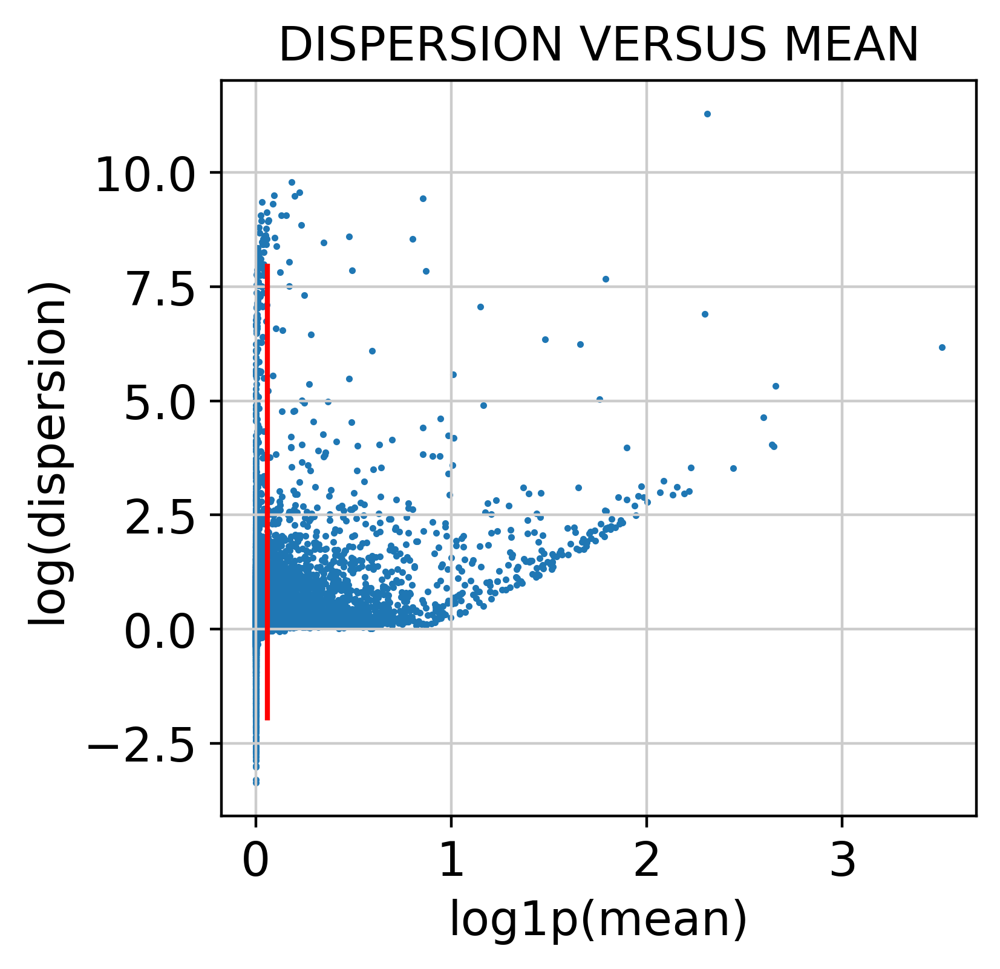

In [22]:
# plot mean versus dispersion plot:
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1,
    
)
plt.vlines(x=np.log1p(min_mean),ymin=-2,ymax=8,color='red')
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

log-transform data:

In [23]:
sc.pp.log1p(combined_data)

now calculate highly variable genes:

In [24]:
sc.pp.highly_variable_genes(combined_data, batch_key="dataset", min_mean=min_mean, flavor="cell_ranger", n_top_genes=2000)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study_long' as categorical
... storing 'study' as categorical
... storing 'last_author_PI' as categorical
... storing 'subject_ID' as categorical
... storing 'subject_ID_as_published' as categorical
... storing 'age_range' as categorical
... storing 'ethnicity' as categorical
... storing 'mixed_ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'smoking_history' as categorical
... storing 'known_lung_disease' as categorical
... storing 'condition' as categorical
... storing 'subject_type' as categorical
... storing 'cause_of_death' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'tissue_dissociation_protocol' as categorical
... storing 'single_cell_platform' as categorical
... storing 'enrichment' as categorical
... storing 'sequ

In [25]:
combined_data.raw = combined_data

Visually check selection of genes:

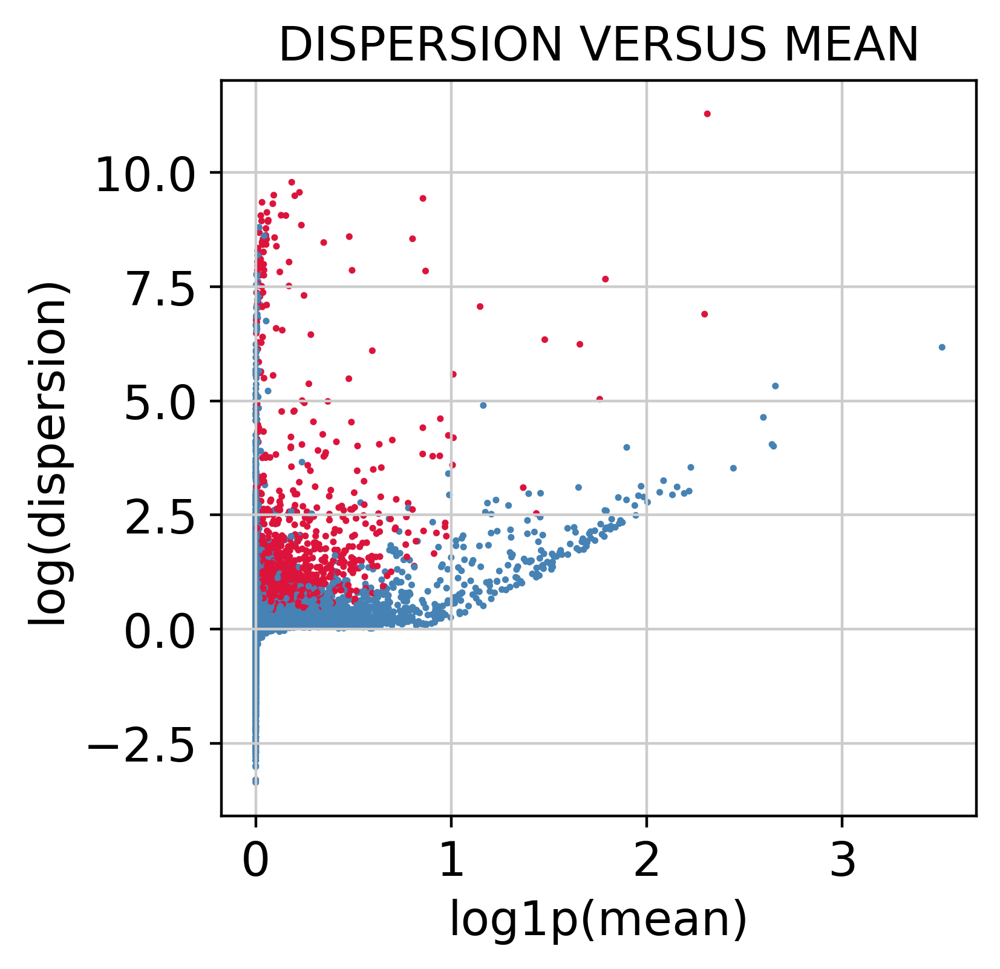

In [26]:
boolean_to_color = {
    True: "crimson",
    False: "steelblue",
}  # make a dictionary that translates the boolean to colors
hvg_colors = combined_data.var.highly_variable.map(boolean_to_color)  # 'convert' the boolean
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1, c=hvg_colors
)
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

Subset data to the calculated top 2000 highly variable genes

In [27]:
combined_data = combined_data[:,combined_data.var.highly_variable].copy()

Go back to raw counts for further learning.

In [28]:
combined_data.X = combined_data.layers["counts"].copy()

### 1.2 scVI and scANVI model with newly calculated HVGs

In this section we do a de-novo integration of query and reference, using highly variable genes calculated on joined reference and query data.

Set parameters to use in all scVI and scANVI models. Use standard parameters as provided in scArches tutorial.

In [11]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

In [32]:
sca.dataset.setup_anndata(combined_data, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             
INFO     Using labels from adata.obs["scanvi_label"]                                         
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
INFO     Please do not further modify adata until model is trained.                          


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [33]:
scvi_model = sca.models.SCVI(
    combined_data,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

First train scVI model, which will be used as starting point for scANVI model.

In [ ]:
scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 328/500:  65%|██████▌   | 327/500 [5:57:42<3:10:30, 66.07s/it, loss=534, v_num=1]

In [ ]:
scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI")

In [37]:
#scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI", combined_data)

Calculate latent embedding of integrated data.

In [ ]:
combined_data.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [ ]:
sc.pp.neighbors(combined_data, use_rep="X_scVI")
sc.tl.leiden(combined_data)
sc.tl.umap(combined_data)

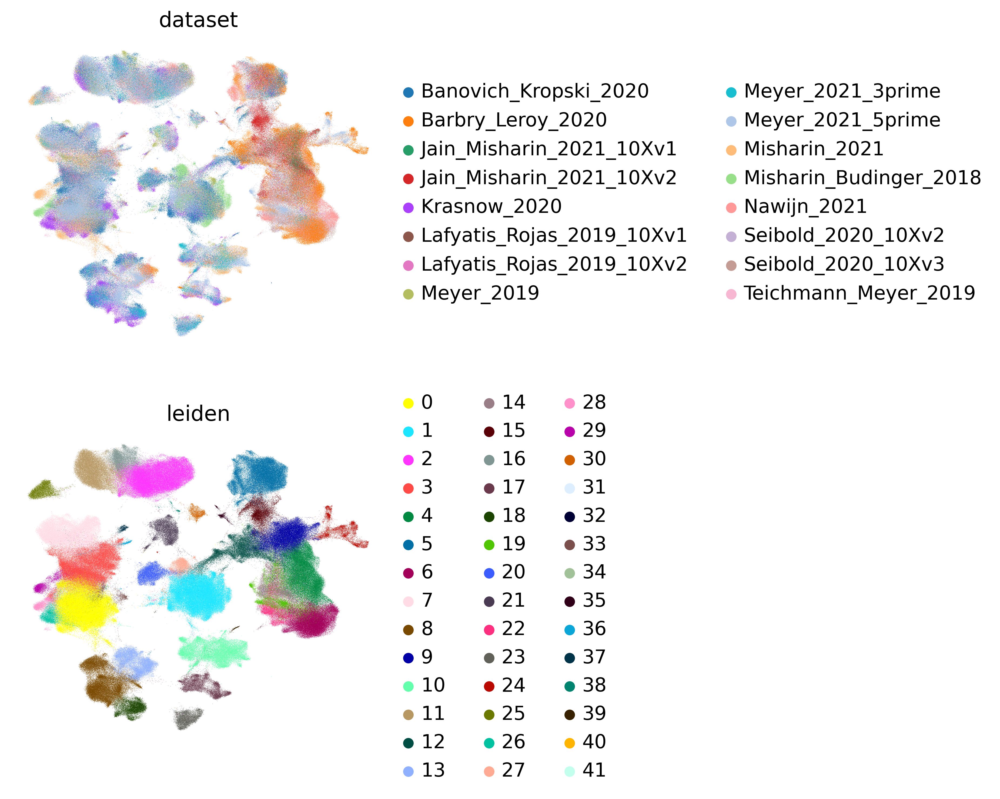

In [52]:
sc.pl.umap(
    combined_data,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

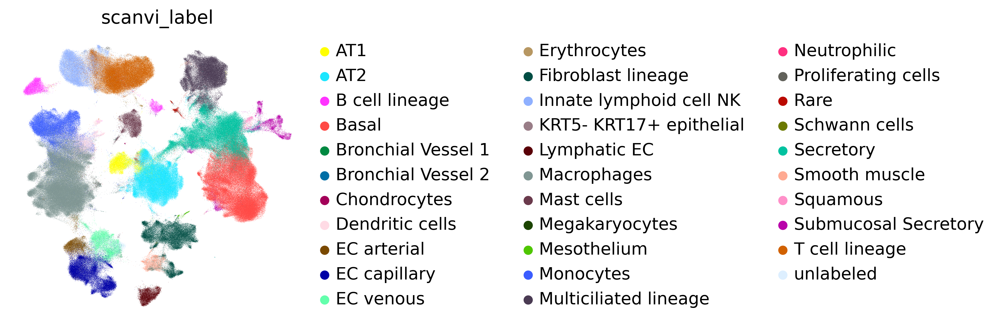

In [53]:
sc.pl.umap(combined_data, color=cell_type_key, frameon=False)

Build scANVI model ontop of scVI model. Therefore load scVI model and then train scANVI model based on it, now including cell type annotations information.

In [ ]:
scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=combined_data)

In [ ]:
scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

In [ ]:
scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI")

In [ ]:
#scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI", combined_data)

In [ ]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Predict cell type annotations and calculate the latent embedding of the integrated data.

In [ ]:
combined_data.obs["C_scANVI"] = scANVI_model.predict(combined_data)
combined_data.obsm["X_scANVI"] = scANVI_model.get_latent_representation(combined_data)

In [ ]:
sc.pp.neighbors(combined_data, use_rep="X_scANVI")
sc.tl.umap(combined_data)

... storing 'highly_variable_intersection-0' as categorical


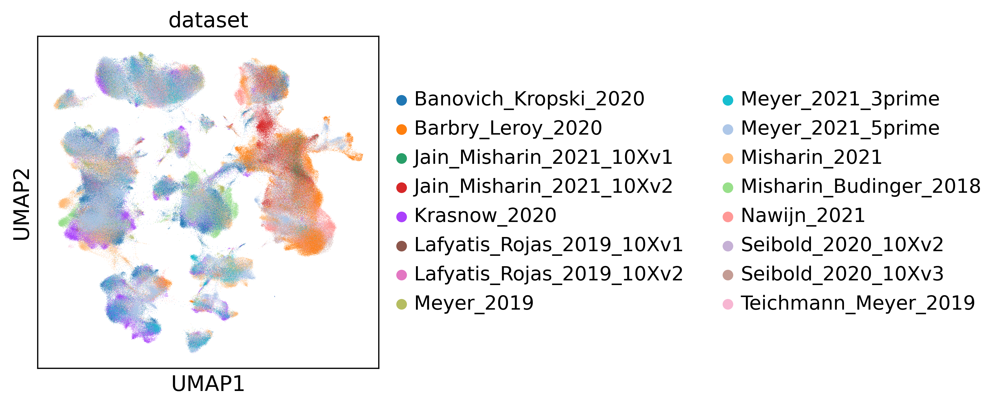

In [12]:
sc.pl.umap(combined_data, color="dataset")

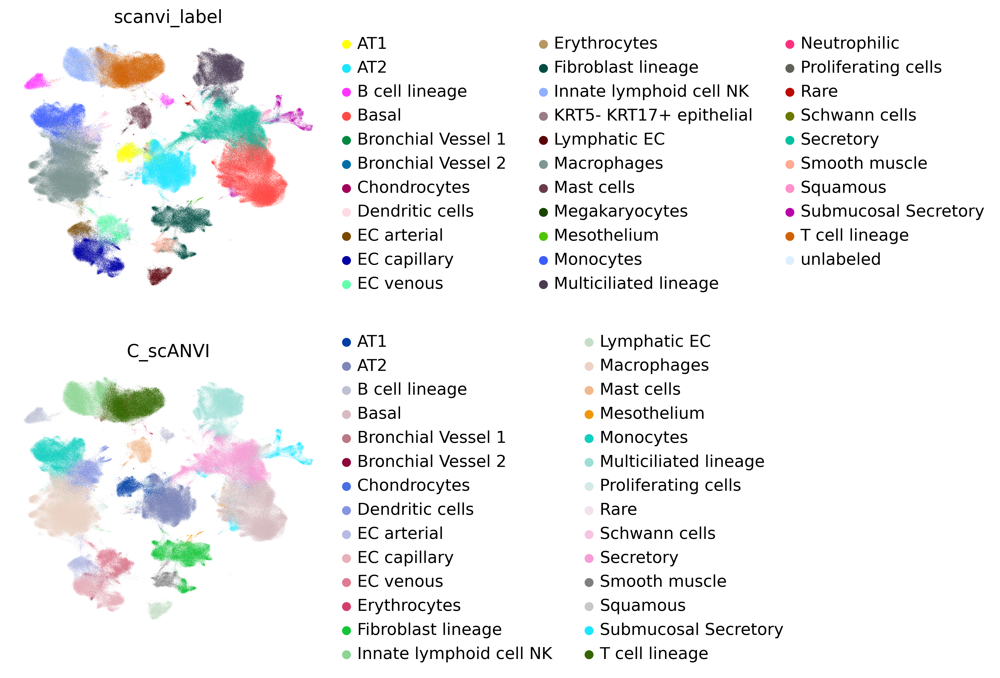

In [54]:
sc.pl.umap(combined_data, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [55]:
df = combined_data.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

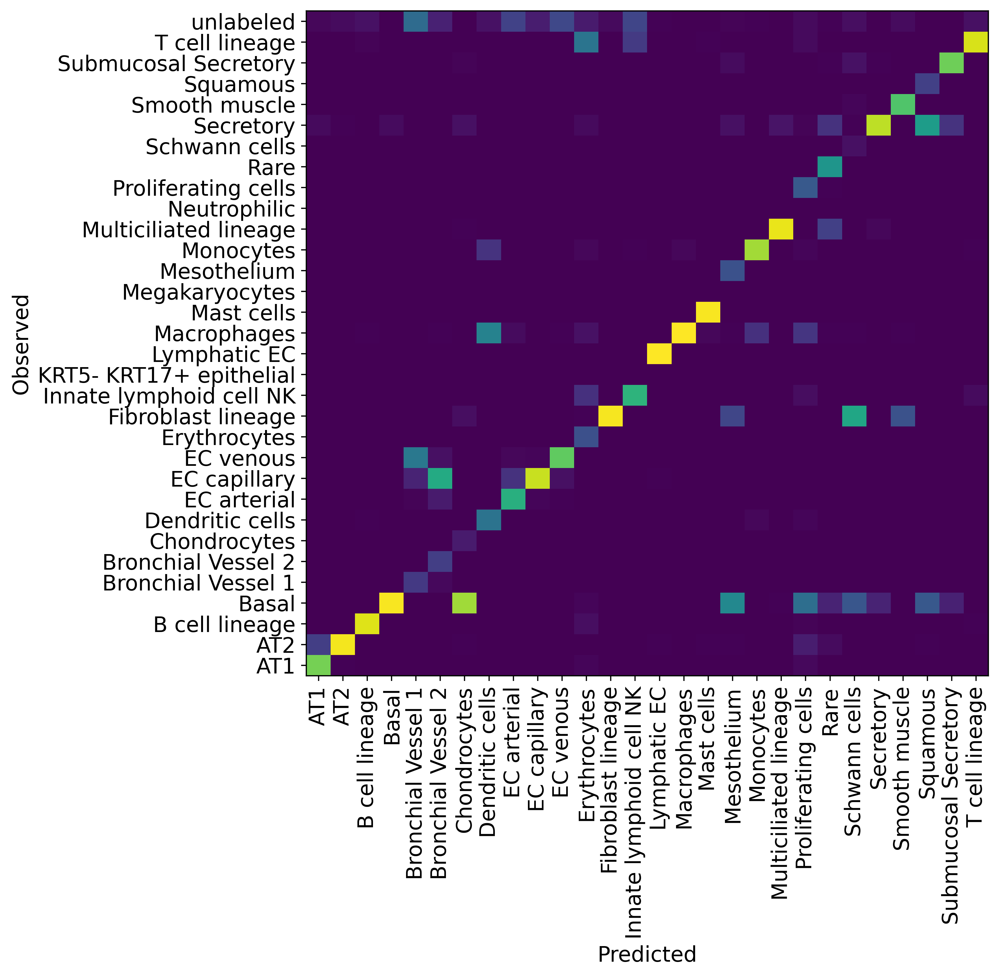

In [56]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo.h5ad")

### 1.3 scVI and scANVI model with old reference HVGs

In this section we do a de-novo integration of query and reference, using the highly variable genes calculated only on the reference data.

In [24]:
sca.dataset.setup_anndata(combined_data_ref_hvg, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             
INFO     Using labels from adata.obs["scanvi_label"]                                         
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
INFO     Please do not further modify adata until model is trained.                          


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [ ]:
scvi_model_ref_hvg = sca.models.SCVI(
    combined_data_ref_hvg,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

First train scVI model, which will be used as starting point for scANVI model.

In [ ]:
scvi_model_ref_hvg.train(max_epochs=scvi_epochs, early_stopping=True)

In [ ]:
scvi_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI_ref_hvg")

In [25]:
scvi_model_ref_hvg = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Calculate latent embedding of integrated data.

In [26]:
combined_data_ref_hvg.obsm["X_scVI"] = scvi_model_ref_hvg.get_latent_representation()

In [27]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scVI")
sc.tl.leiden(combined_data_ref_hvg)
sc.tl.umap(combined_data_ref_hvg)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study_long' as categorical
... storing 'study' as categorical
... storing 'last_author_PI' as categorical
... storing 'subject_ID' as categorical
... storing 'subject_ID_as_published' as categorical
... storing 'age_range' as categorical
... storing 'ethnicity' as categorical
... storing 'mixed_ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'smoking_history' as categorical
... storing 'known_lung_disease' as categorical
... storing 'condition' as categorical
... storing 'subject_type' as categorical
... storing 'cause_of_death' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'tissue_dissociation_protocol' as categorical
... storing 'single_cell_platform' as categorical
... storing 'enrichment' as categorical
... storing 'sequ

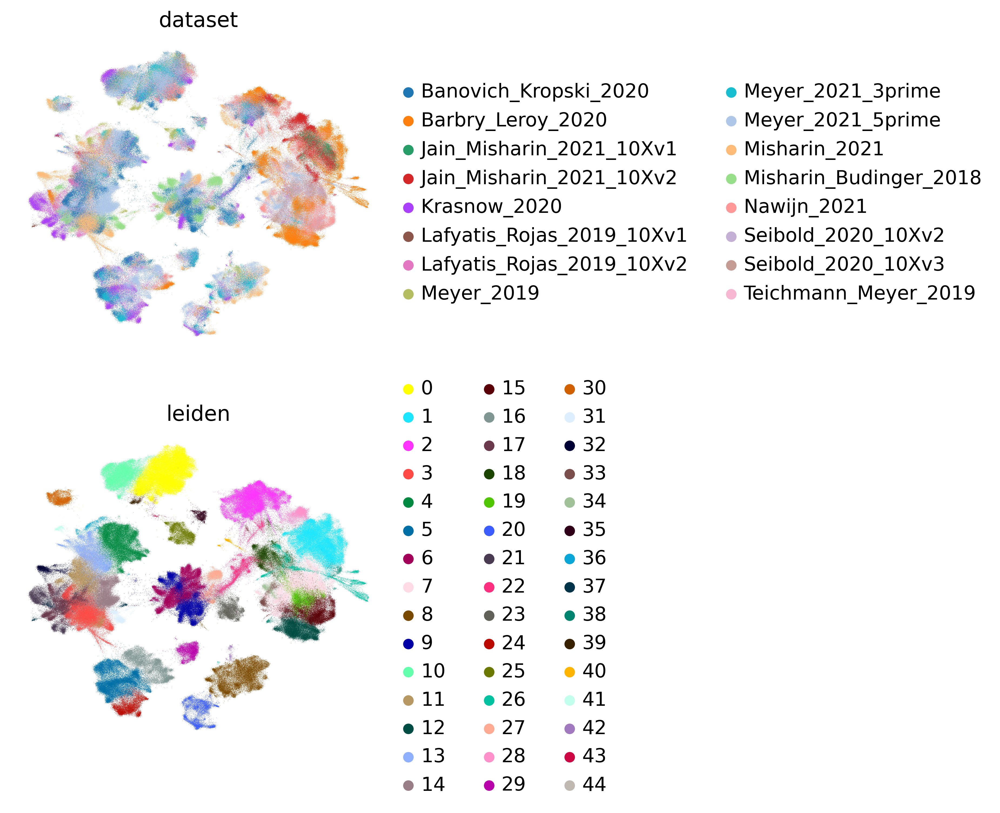

In [28]:
sc.pl.umap(
    combined_data_ref_hvg,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

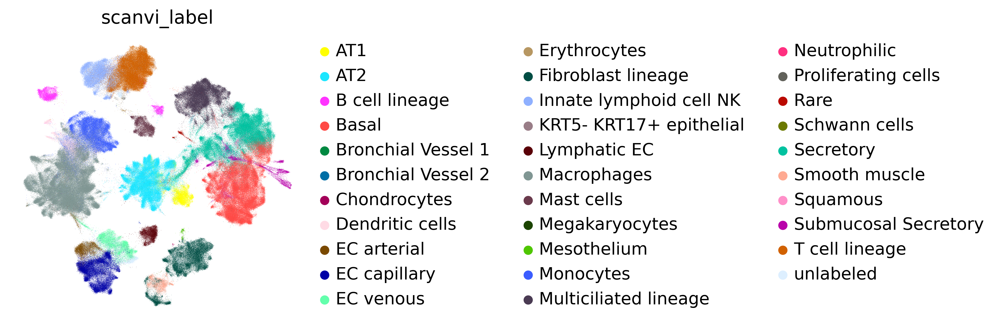

In [29]:
sc.pl.umap(combined_data_ref_hvg, color=cell_type_key, frameon=False)

Build scANVI model ontop of scVI model. Therefore load scVI model and then train scANVI model based on it, now including cell type annotations information.

In [30]:
scANVI_model_ref_hvg = sca.models.SCANVI.from_scvi_model(scvi_model_ref_hvg, unlabeled_category, adata=combined_data_ref_hvg)

In [31]:
scANVI_model_ref_hvg.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 188/200:  94%|█████████▍| 188/200 [4:31:53<17:21, 86.77s/it, loss=691, v_num=1]  


In [32]:
scANVI_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI_ref_hvg")

In [33]:
scANVI_model_ref_hvg = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [34]:
print("Labelled Indices: ", len(scANVI_model_ref_hvg._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model_ref_hvg._unlabeled_indices))

Labelled Indices:  689338
Unlabelled Indices:  24174


Predict cell type annotations and calculate the latent embedding of the integrated data.

In [35]:
combined_data_ref_hvg.obs["C_scANVI"] = scANVI_model_ref_hvg.predict(combined_data_ref_hvg)
combined_data_ref_hvg.obsm["X_scANVI"] = scANVI_model_ref_hvg.get_latent_representation(combined_data_ref_hvg)

In [36]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scANVI")
sc.tl.umap(combined_data_ref_hvg)

... storing 'highly_variable_intersection-0' as categorical


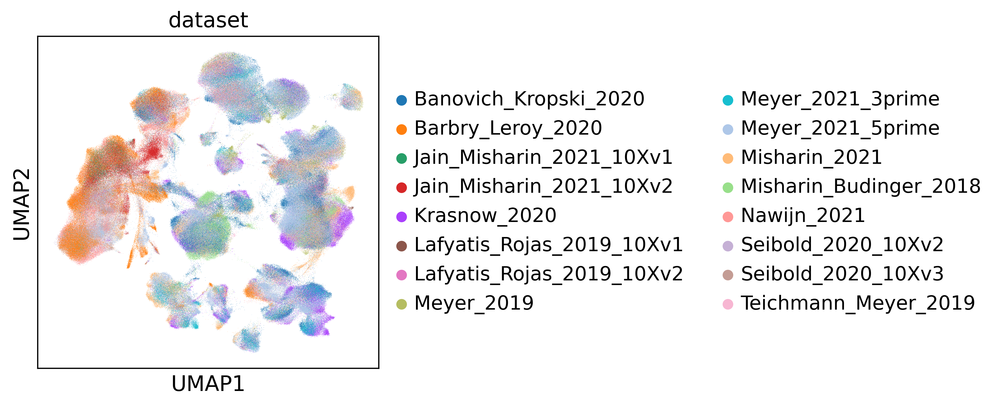

In [14]:
sc.pl.umap(combined_data_ref_hvg, color="dataset")

... storing 'C_scANVI' as categorical


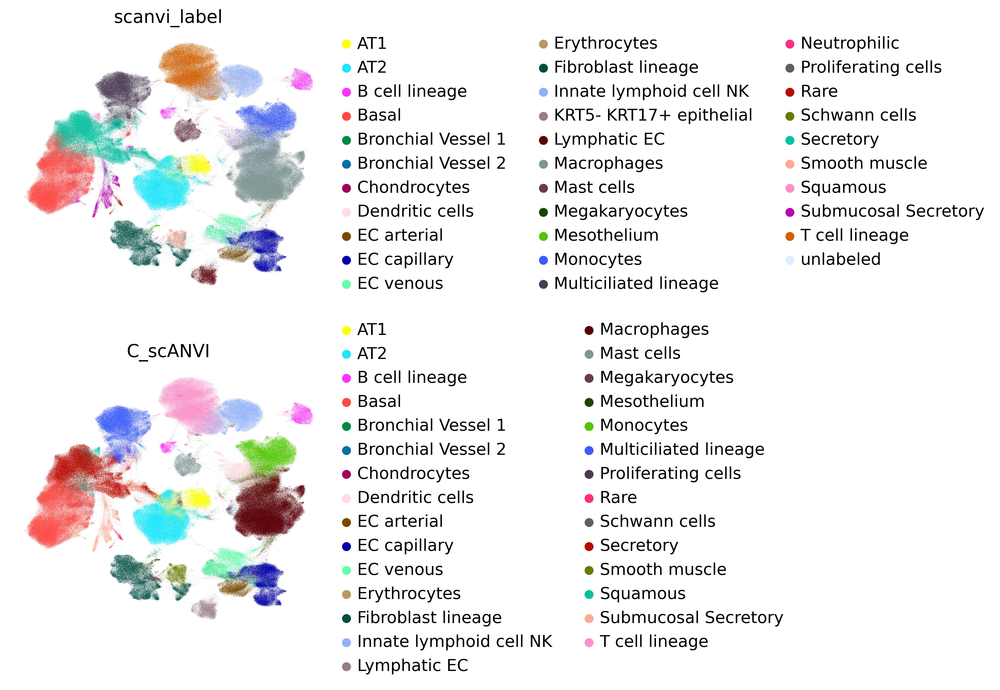

In [37]:
sc.pl.umap(combined_data_ref_hvg, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [38]:
df = combined_data_ref_hvg.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

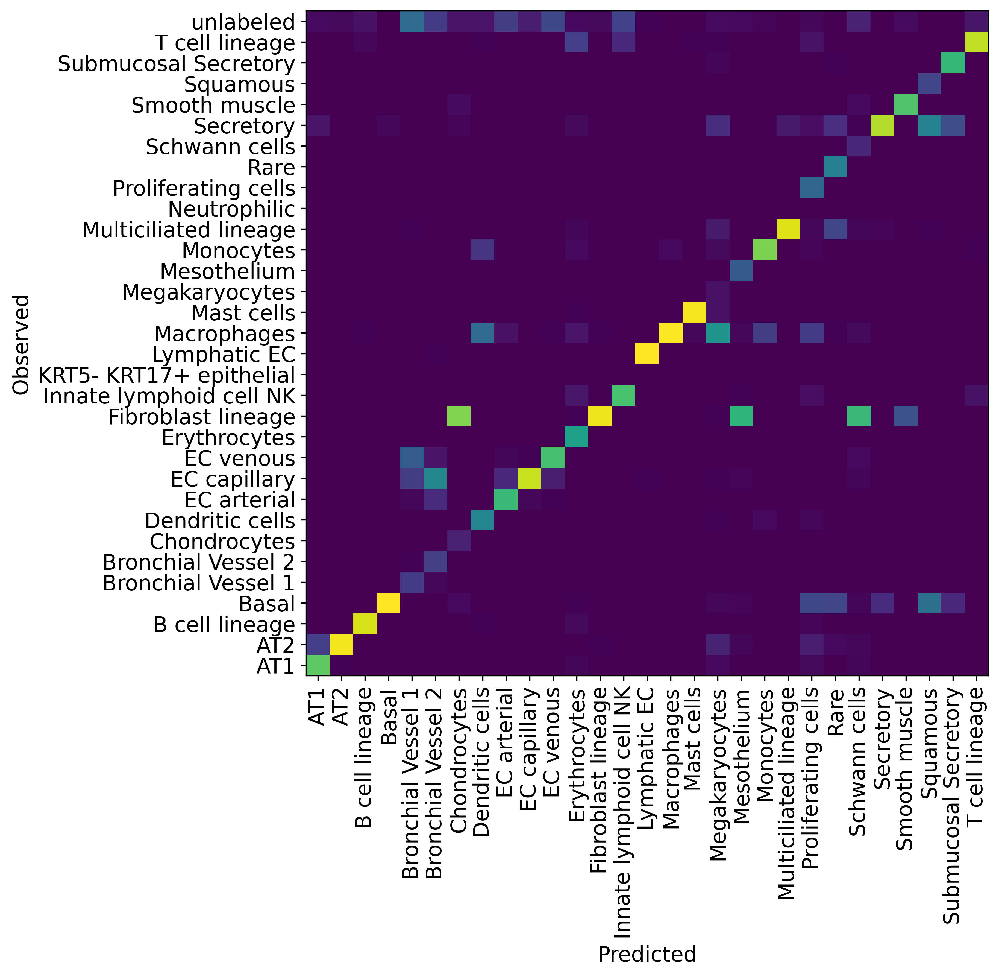

In [39]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [40]:
combined_data_ref_hvg.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo_ref_hvg.h5ad")

## 2. scArches | Perform surgery 

In this section we will use the transfer learning approach/model scArches to integrate reference and query data.

### 2.1 Unlabeled scArches

Use scArches without the information of the labels. Therefore set all labels of query to "unlabeled".

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set all labels to unlabeled

In [12]:
scANVI_model_original = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", atlas_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [13]:
query_data.obs["scanvi_label_original"]=query_data.obs["scanvi_label"]

In [14]:
query_data.obs["scanvi_label"]=scANVI_model_original.unlabeled_category_

For scArches the genes in reference and query have to be the same and in the same order.

In [15]:
query_data_scArches = query_data[:,atlas_data.var.gene_ids].copy()

scArches model is build on top of scANVI model of the original reference atlas.

In [45]:
scArches_model = sca.models.SCANVI.load_query_data(
    query_data_scArches,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model._unlabeled_indices = np.arange(query_data_scArches.n_obs)
scArches_model._labeled_indices = []
print("Labelled Indices: ", len(scArches_model._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model._unlabeled_indices))

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 128628 cells, 2000 vars, 16       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
Labelled Indices:  0
Unlabelled Indices:  128628


In [46]:
scArches_model.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [34:59<00:00, 10.50s/it, loss=505, v_num=1]


Concatenate original reference atlas and the newly learned query atlas to get one common representation. For this, predict the cell type annotations and calculate the latent representation of the integration.

In [47]:
query_data_scArches_full = atlas_data.concatenate(query_data_scArches)
query_data_scArches_full.obs["C_scArches"] = scArches_model.predict(query_data_scArches_full)
query_data_scArches_full.obsm["X_scArches"] = scArches_model.get_latent_representation(query_data_scArches_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [48]:
sc.pp.neighbors(query_data_scArches_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_full)

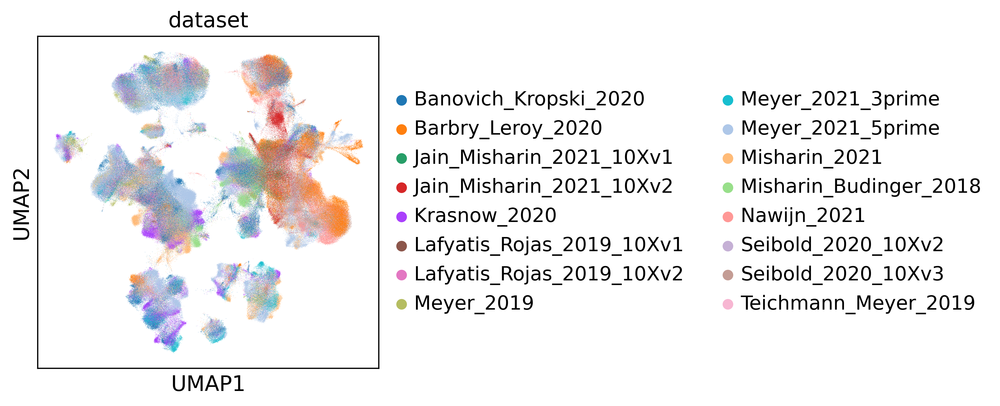

In [17]:
sc.pl.umap(query_data_scArches_full, color="dataset")

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study_long' as categorical
... storing 'study' as categorical
... storing 'last_author_PI' as categorical
... storing 'subject_ID' as categorical
... storing 'subject_ID_as_published' as categorical
... storing 'age_range' as categorical
... storing 'ethnicity' as categorical
... storing 'mixed_ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'smoking_history' as categorical
... storing 'known_lung_disease' as categorical
... storing 'condition' as categorical
... storing 'subject_type' as categorical
... storing 'cause_of_death' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'tissue_dissociation_protocol' as categorical
... storing 'single_cell_platform' as categorical
... storing 'enrichment' as categorical
... storing 'sequ

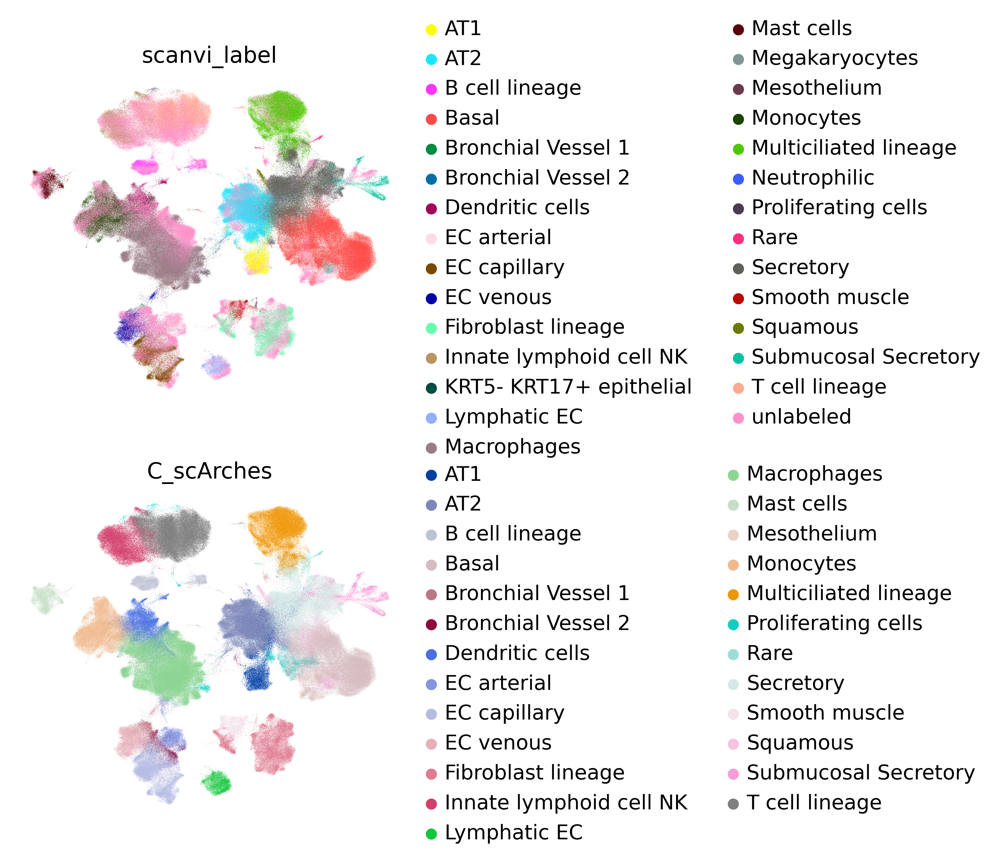

In [49]:
sc.pl.umap(query_data_scArches_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [50]:
df = query_data_scArches_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

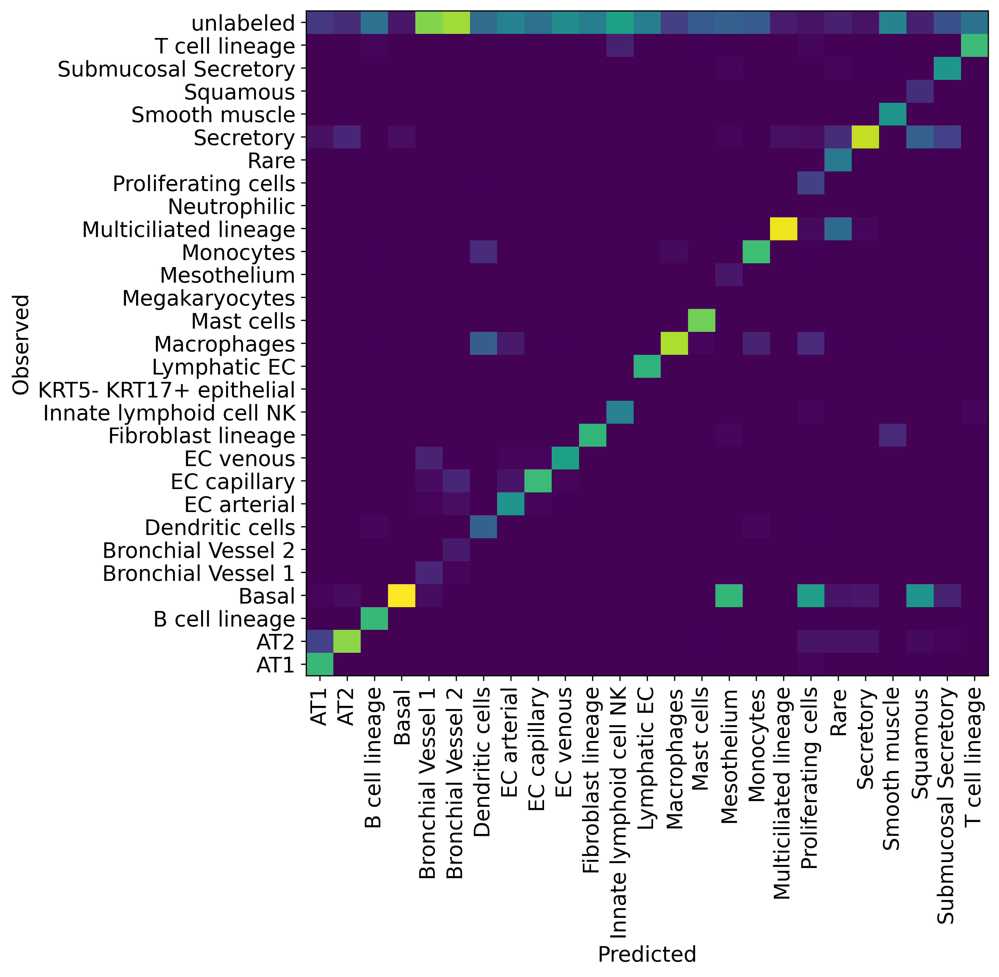

In [51]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [52]:
query_data_scArches_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_full.h5ad")

### 2.2 Labeled scArches

Use scArches with the information of the labels. Make sure that all labels in the query data are contained in the original reference atlas, if not, set them to "unlabeled".

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set labels to unlabeled which are not in the atlas

In [16]:
mask_unlabeled = [x for x in set(query_data.obs.scanvi_label_original) if x not in set(atlas_data.obs.scanvi_label)]

In [17]:
set(query_data.obs.scanvi_label_original)

{'AT1',
 'AT2',
 'B cell lineage',
 'Basal',
 'Chondrocytes',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Erythrocytes',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Megakaryocytes',
 'Mesothelium',
 'Monocytes',
 'Multiciliated lineage',
 'Rare',
 'Schwann cells',
 'Secretory',
 'Smooth muscle',
 'Submucosal Secretory',
 'T cell lineage'}

In [18]:
set(atlas_data.obs.scanvi_label)

{'AT1',
 'AT2',
 'B cell lineage',
 'Basal',
 'Bronchial Vessel 1',
 'Bronchial Vessel 2',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'KRT5- KRT17+ epithelial',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Megakaryocytes',
 'Mesothelium',
 'Monocytes',
 'Multiciliated lineage',
 'Neutrophilic',
 'Proliferating cells',
 'Rare',
 'Secretory',
 'Smooth muscle',
 'Squamous',
 'Submucosal Secretory',
 'T cell lineage',
 'unlabeled'}

In [19]:
mask_unlabeled

['Chondrocytes', 'Erythrocytes', 'Schwann cells']

In [20]:
query_data.obs["scanvi_label"][query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = scANVI_model_original.unlabeled_category_

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [21]:
query_data.obs["scanvi_label"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = query_data.obs["scanvi_label_original"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)]

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


For scArches the genes in reference and query have to be the same and in the same order.

In [22]:
query_data_scArches_labeled = query_data[:,atlas_data.var.gene_ids].copy()

In [23]:
[x for x in set(query_data_scArches_labeled.obs.scanvi_label) if x not in set(atlas_data.obs.scanvi_label)]
# if empty set, then all labels in query data are in atlas data contained

[]

scArches model is build on top of scANVI model of the original reference atlas.

In [61]:
scArches_model_labeled = sca.models.SCANVI.load_query_data(
    query_data_scArches_labeled,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model_labeled._unlabeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]==scArches_model_labeled.unlabeled_category_))[0]
scArches_model_labeled._labeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]!=scArches_model_labeled.unlabeled_category_))[0]
print("Labelled Indices: ", len(scArches_model_labeled._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model_labeled._unlabeled_indices))

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 128628 cells, 2000 vars, 16       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
Labelled Indices:  128222
Unlabelled Indices:  406


In [ ]:
scArches_model_labeled.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 46/200:  22%|██▎       | 45/200 [09:28<32:14, 12.48s/it, loss=616, v_num=1]

Concatenate original reference atlas and the newly learned query atlas to get one common representation. For this, predict the cell type annotations and calculate the latent representation of the integration.

In [ ]:
query_data_scArches_labeled_full = atlas_data.concatenate(query_data_scArches_labeled)
query_data_scArches_labeled_full.obs["C_scArches"] = scArches_model_labeled.predict(query_data_scArches_labeled_full)
query_data_scArches_labeled_full.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation(query_data_scArches_labeled_full)

In [ ]:
sc.pp.neighbors(query_data_scArches_labeled_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_labeled_full)

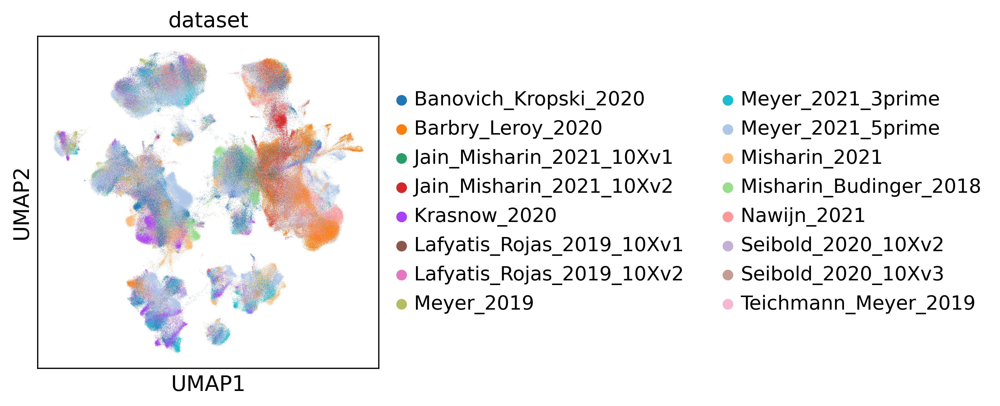

In [20]:
sc.pl.umap(query_data_scArches_labeled_full, color="dataset")

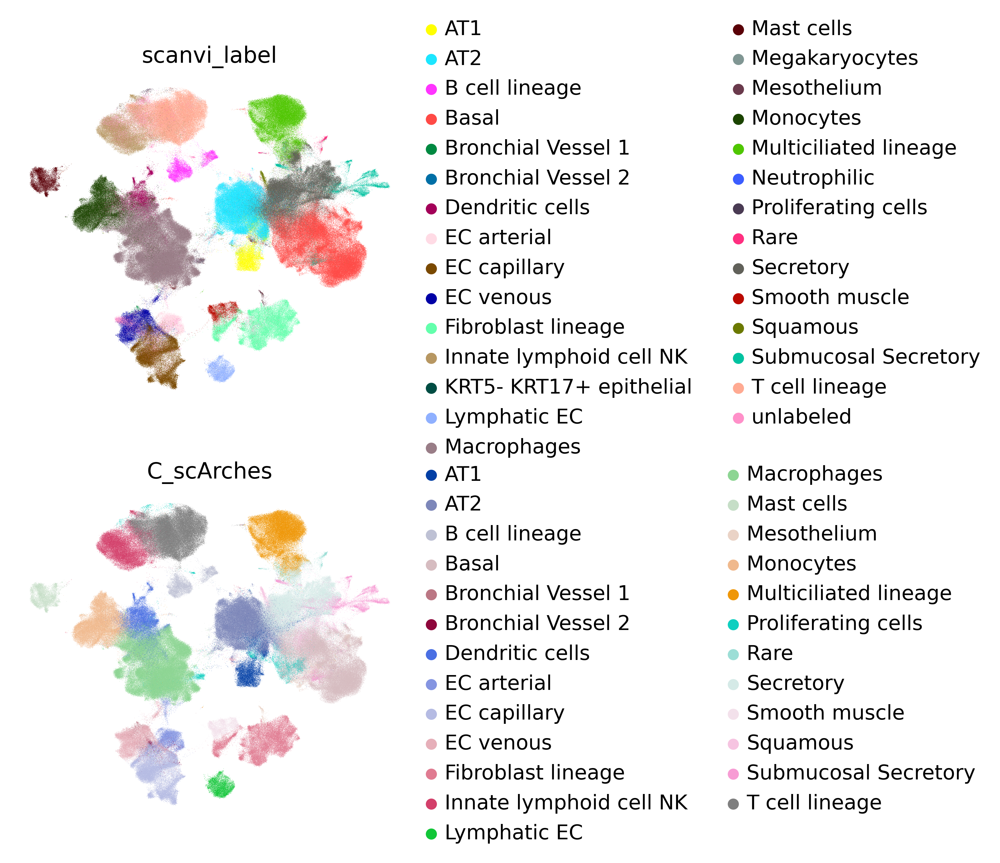

In [6]:
sc.pl.umap(query_data_scArches_labeled_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

Calculate and plot confusion matrix.

In [7]:
df = query_data_scArches_labeled_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

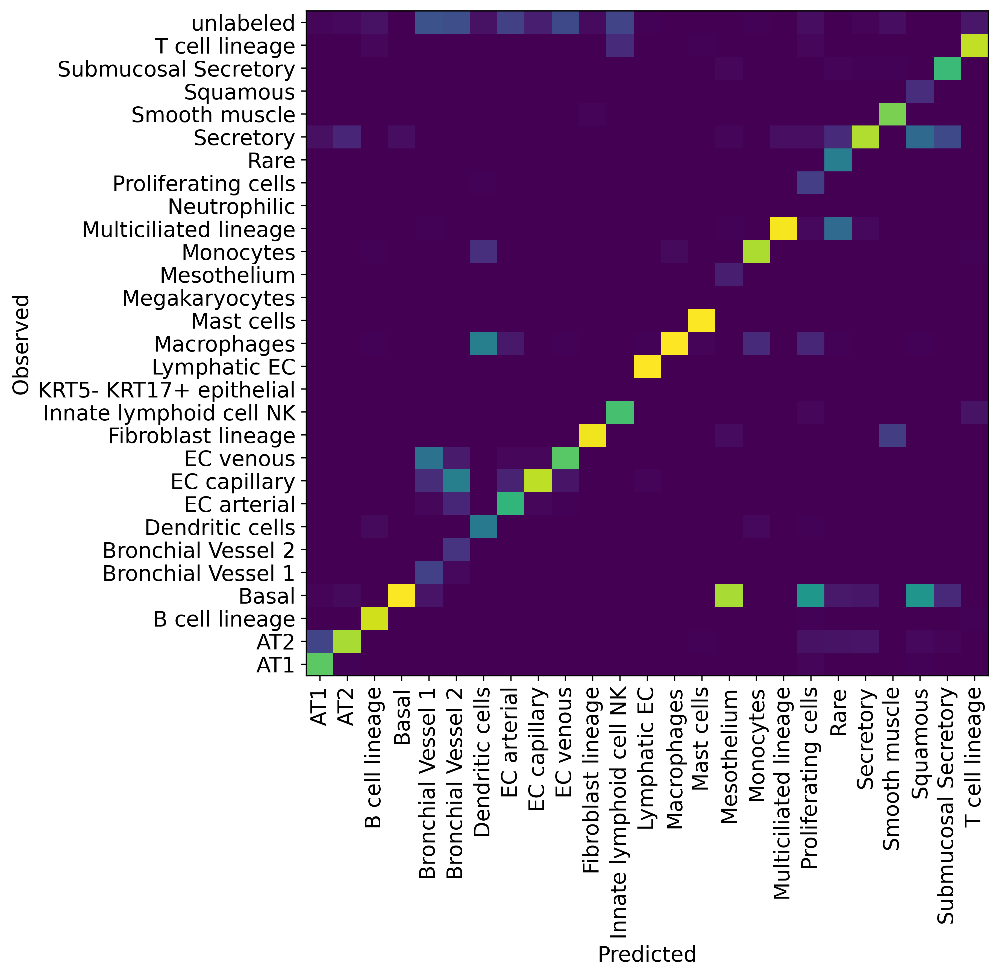

In [8]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
query_data_scArches_labeled_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_labeled_full.h5ad")

Logging

In [9]:
sc.logging.print_versions()

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.6
scanpy      1.8.1
sinfo       0.3.4
-----
PIL                         8.3.1
absl                        NA
anyio                       NA
attr                        21.2.0
babel                       2.9.1
backcall                    0.2.0
beta_ufunc                  NA
binom_ufunc                 NA
bottleneck                  1.3.2
brotli                      NA
certifi                     2021.10.08
cffi                        1.14.6
chardet                     4.0.0
charset_normali